In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load dataset
df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
# Check column data types
print("Data types:")
display(df.dtypes)

# Check missing values
print("\nMissing values:")
print(df.isnull().sum())

# Check duplicated rows
print("\nDuplicated rows:", df.duplicated().sum())

# Check dataset information
print("\nDataset information:")
df.info()

Data types:


customerID              str
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges            str
Churn                   str
dtype: object


Missing values:
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

Duplicated rows: 0

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   in

In [4]:
# Check unique examples
print("TotalCharges examples:")
print(df["TotalCharges"].head(10))

# Check empty strings and spaces
empty_values = df["TotalCharges"].str.strip() == ""

print("\nEmpty TotalCharges values:")
print(empty_values.sum())

# Check data types
print("\nTotalCharges data type:")
print(df["TotalCharges"].dtype)

# Check duplicates
print("\nDuplicated rows:", df.duplicated().sum())

TotalCharges examples:
0      29.85
1     1889.5
2     108.15
3    1840.75
4     151.65
5      820.5
6     1949.4
7      301.9
8    3046.05
9    3487.95
Name: TotalCharges, dtype: str

Empty TotalCharges values:
11

TotalCharges data type:
str

Duplicated rows: 0


In [5]:
# Convert TotalCharges from text to numbers
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"],
    errors="coerce"
)

# Check missing values after conversion
print("Missing TotalCharges:", df["TotalCharges"].isnull().sum())

# Investigate affected customers
display(df[df["TotalCharges"].isnull()][["tenure", "TotalCharges"]])

Missing TotalCharges: 11


,tenure,TotalCharges
488,0,NaN
753,0,NaN
936,0,NaN
1082,0,NaN
1340,0,NaN
3331,0,NaN
3826,0,NaN
4380,0,NaN
5218,0,NaN
6670,0,NaN


In [6]:
# Fill missing TotalCharges with 0
df["TotalCharges"] = df["TotalCharges"].fillna(0)

# Verify
print("Missing values:", df["TotalCharges"].isnull().sum())
print("New data type:", df["TotalCharges"].dtype)

Missing values: 0
New data type: float64


In [7]:
# Save the true labels separately
y_true = df["Churn"].copy()

# Check the labels
print(y_true.value_counts())

Churn
No     5174
Yes    1869
Name: count, dtype: int64


In [8]:
# Remove customerID and Churn
X = df.drop(columns=["customerID", "Churn"])

# Check the new dataset
print("Features shape:", X.shape)
display(X.head())

Features shape: (7043, 19)


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65


In [9]:
print(X.dtypes)

gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges        float64
dtype: object


In [10]:
# Identify numerical columns
numerical_cols = [
    "SeniorCitizen",
    "tenure",
    "MonthlyCharges",
    "TotalCharges"
]

# Identify categorical columns
categorical_cols = X.select_dtypes(include=["str", "object"]).columns.tolist()

print("Numerical columns:", numerical_cols)
print("\nCategorical columns:", categorical_cols)

print("\nNumber of numerical features:", len(numerical_cols))
print("Number of categorical features:", len(categorical_cols))

Numerical columns: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']

Categorical columns: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']

Number of numerical features: 4
Number of categorical features: 15


In [11]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_cols),
        ("cat", OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False
        ), categorical_cols)
    ]
)

# Transform the dataset
X_processed = preprocessor.fit_transform(X)

print("Original shape:", X.shape)
print("Processed shape:", X_processed.shape)

Original shape: (7043, 19)
Processed shape: (7043, 45)


In [12]:
print("Processed data shape:", X_processed.shape)

print("\nMissing values:", np.isnan(X_processed).sum())

print("\nFirst 5 processed rows:")
display(pd.DataFrame(X_processed).head())

Processed data shape: (7043, 45)

Missing values: 0

First 5 processed rows:


,0,1,2,3,4,5,6,7,8,9,...,35,36,37,38,39,40,41,42,43,44
0,-0.439916,-1.277445,-1.160323,-0.992611,1.0,0.0,0.0,1.0,1.0,0.0,...,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
1,-0.439916,0.066327,-0.259629,-0.172165,0.0,1.0,1.0,0.0,1.0,0.0,...,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
2,-0.439916,-1.236724,-0.362660,-0.958066,0.0,1.0,1.0,0.0,1.0,0.0,...,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
3,-0.439916,0.514251,-0.746535,-0.193672,0.0,1.0,1.0,0.0,1.0,0.0,...,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0
4,-0.439916,-1.236724,0.197365,-0.938874,1.0,0.0,1.0,0.0,1.0,0.0,...,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0


In [ ]:
###########################

In [13]:
from sklearn.cluster import KMeans

kmeans = KMeans(
    n_clusters=3,
    init="k-means++", #choose good starting centroids to improve initialization 
    n_init=10, # try 10 different initialization and keep the best results 
    random_state=42
)

cluster_labels = kmeans.fit_predict(X_processed)

print("First 20 cluster assignments:")
print(cluster_labels[:20])

print("\nNumber of customers in each cluster:")
print(pd.Series(cluster_labels).value_counts().sort_index())

print("\nInertia:", kmeans.inertia_)

First 20 cluster assignments:
[1 1 1 1 1 1 1 1 2 2 1 0 2 2 1 2 0 2 1 1]

Number of customers in each cluster:
0    1526
1    3189
2    2328
Name: count, dtype: int64

Inertia: 55586.85345796538


In [14]:
inertia_values = []
k_values = range(2, 11)

for k in k_values:
    model = KMeans(
        n_clusters=k,
        init="k-means++",
        n_init=10,
        random_state=42
    )

    model.fit(X_processed)

    inertia_values.append(model.inertia_)

    print(f"K = {k}, Inertia = {model.inertia_:.2f}")

K = 2, Inertia = 68648.35
K = 3, Inertia = 55586.85
K = 4, Inertia = 50813.27
K = 5, Inertia = 47871.27
K = 6, Inertia = 45698.66
K = 7, Inertia = 43809.60
K = 8, Inertia = 42031.39
K = 9, Inertia = 40929.55
K = 10, Inertia = 39895.00


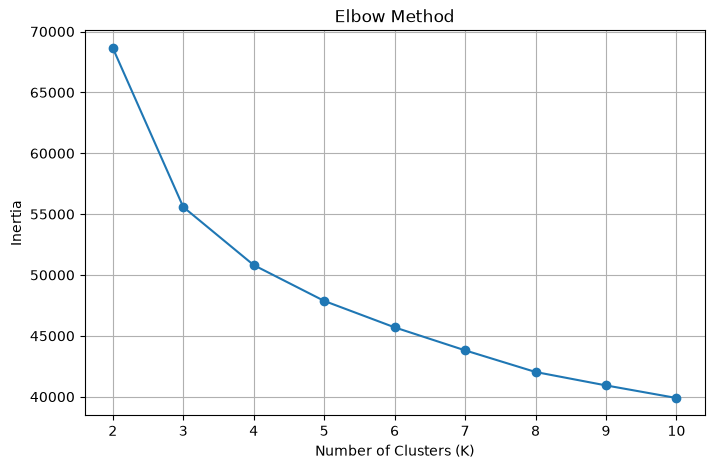

In [15]:
plt.figure(figsize=(8, 5))

plt.plot(
    k_values,
    inertia_values,
    marker="o"
)

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method")
plt.xticks(list(k_values))
plt.grid(True)

plt.show()


In [16]:
from sklearn.metrics import silhouette_score

silhouette_values = []

for k in range(2, 11):

    model = KMeans(
        n_clusters=k,
        init="k-means++",
        n_init=10,
        random_state=42
    )

    labels = model.fit_predict(X_processed)

    score = silhouette_score(
        X_processed,
        labels,
        sample_size=2000,
        random_state=42
    )

    silhouette_values.append(score)

    print(f"K = {k}, Silhouette Score = {score:.4f}")
    

K = 2, Silhouette Score = 0.2353
K = 3, Silhouette Score = 0.2383
K = 4, Silhouette Score = 0.2305
K = 5, Silhouette Score = 0.1960
K = 6, Silhouette Score = 0.1856
K = 7, Silhouette Score = 0.1890
K = 8, Silhouette Score = 0.1555
K = 9, Silhouette Score = 0.1408
K = 10, Silhouette Score = 0.1398


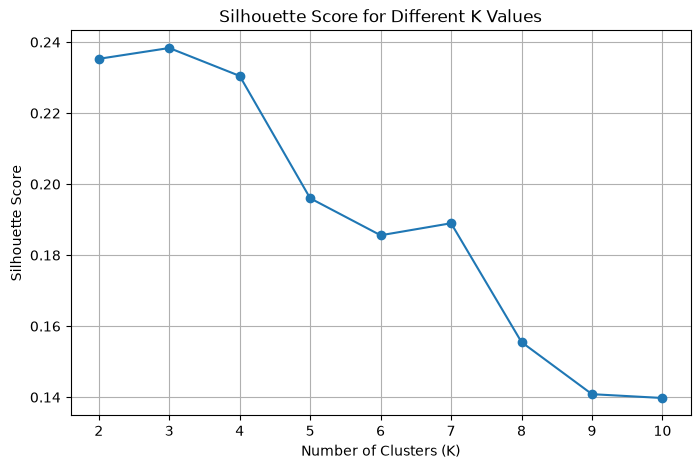

In [17]:
plt.figure(figsize=(8, 5))

plt.plot(
    range(2, 11),
    silhouette_values,
    marker="o"
)

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Score for Different K Values")
plt.xticks(range(2, 11))
plt.grid(True)

plt.show()

In [18]:
seeds = [10, 20, 42, 100, 2026]

for seed in seeds:

    model = KMeans(
        n_clusters=3,
        init="k-means++",
        n_init=10,
        random_state=seed
    )

    labels = model.fit_predict(X_processed)

    print(f"\nRandom Seed: {seed}")
    print(f"Inertia: {model.inertia_:.2f}")

    print("Cluster sizes:")
    print(pd.Series(labels).value_counts().sort_index())


Random Seed: 10
Inertia: 55586.85
Cluster sizes:
0    1526
1    2328
2    3189
Name: count, dtype: int64

Random Seed: 20
Inertia: 55586.85
Cluster sizes:
0    2328
1    3189
2    1526
Name: count, dtype: int64

Random Seed: 42
Inertia: 55586.85
Cluster sizes:
0    1526
1    3189
2    2328
Name: count, dtype: int64

Random Seed: 100
Inertia: 55586.85
Cluster sizes:
0    3188
1    2329
2    1526
Name: count, dtype: int64

Random Seed: 2026
Inertia: 55586.85
Cluster sizes:
0    3189
1    1526
2    2328
Name: count, dtype: int64


In [19]:
from sklearn.metrics import adjusted_rand_score

seeds = [10, 20, 42, 100, 2026]

all_labels = {}

for seed in seeds:

    model = KMeans(
        n_clusters=3,
        init="k-means++",
        n_init=10,
        random_state=seed
    )

    labels = model.fit_predict(X_processed)

    all_labels[seed] = labels


print("Adjusted Rand Index compared with seed 42:\n")

for seed in seeds:

    if seed != 42:

        ari = adjusted_rand_score(
            all_labels[42],
            all_labels[seed]
        )

        print(f"Seed 42 vs Seed {seed}: {ari:.4f}")

Adjusted Rand Index compared with seed 42:

Seed 42 vs Seed 10: 1.0000
Seed 42 vs Seed 20: 1.0000
Seed 42 vs Seed 100: 0.9995
Seed 42 vs Seed 2026: 1.0000


In [20]:
final_kmeans = KMeans(
    n_clusters=3,
    init="k-means++",
    n_init=10,
    random_state=42
)

final_labels = final_kmeans.fit_predict(X_processed)

In [21]:
comparison = pd.crosstab(
    final_labels,
    y_true,
    rownames=["Cluster"],
    colnames=["Actual Churn"]
)

print(comparison)

Actual Churn    No   Yes
Cluster                 
0             1413   113
1             1785  1404
2             1976   352


In [22]:
churn_rates = comparison.div(comparison.sum(axis=1), axis=0) * 100

print(churn_rates.round(2))


Actual Churn     No    Yes
Cluster                   
0             92.60   7.40
1             55.97  44.03
2             84.88  15.12


In [23]:
clustered_df = X.copy()

clustered_df["Cluster"] = final_labels
clustered_df["Churn"] = y_true.values

print("Average numerical features by cluster:")

display(
    clustered_df.groupby("Cluster")[
        ["tenure", "MonthlyCharges", "TotalCharges"]
    ].mean().round(2)
)

Average numerical features by cluster:


,tenure,MonthlyCharges,TotalCharges
Cluster,,,
0,30.55,21.08,662.60
1,15.30,67.86,1018.08
2,56.95,89.15,5068.03


In [24]:
categorical_features = [
    "Contract",
    "InternetService",
    "PaymentMethod",
    "OnlineSecurity",
    "TechSupport"
]

for col in categorical_features:

    print(f"\n{'='*50}")
    print(f"{col} distribution by cluster (%)")
    print('='*50)

    display(
        pd.crosstab(
            clustered_df["Cluster"],
            clustered_df[col],
            normalize="index"
        ).mul(100).round(2)
    )


Contract distribution by cluster (%)


Contract,Month-to-month,One year,Two year
Cluster,,,
0,34.34,23.85,41.81
1,87.02,10.50,2.48
2,24.74,33.25,42.01



InternetService distribution by cluster (%)


InternetService,DSL,Fiber optic,No
Cluster,,,
0,0.00,0.00,100.0
1,47.66,52.34,0.0
2,38.70,61.30,0.0



PaymentMethod distribution by cluster (%)


PaymentMethod,Bank transfer (automatic),Credit card (automatic),Electronic check,Mailed check
Cluster,,,,
0,21.76,21.69,7.99,48.56
1,14.46,14.77,49.33,21.45
2,32.26,30.93,28.78,8.03



OnlineSecurity distribution by cluster (%)


OnlineSecurity,No,No internet service,Yes
Cluster,,,
0,0.00,100.0,0.00
1,76.42,0.0,23.58
2,45.58,0.0,54.42



TechSupport distribution by cluster (%)


TechSupport,No,No internet service,Yes
Cluster,,,
0,0.00,100.0,0.00
1,77.74,0.0,22.26
2,42.70,0.0,57.30


In [25]:
from sklearn.decomposition import PCA
pca = PCA(n_components=2)

In [26]:
X_pca = pca.fit_transform(X_processed)

print("Original shape:", X_processed.shape)
print("PCA shape:", X_pca.shape)

Original shape: (7043, 45)
PCA shape: (7043, 2)


In [27]:
explained_variance = pca.explained_variance_ratio_

print("PC1:", explained_variance[0] * 100, "%")
print("PC2:", explained_variance[1] * 100, "%")
print("Total:", explained_variance.sum() * 100, "%")


PC1: 27.22053805330586 %
PC2: 18.099002834537814 %
Total: 45.31954088784367 %


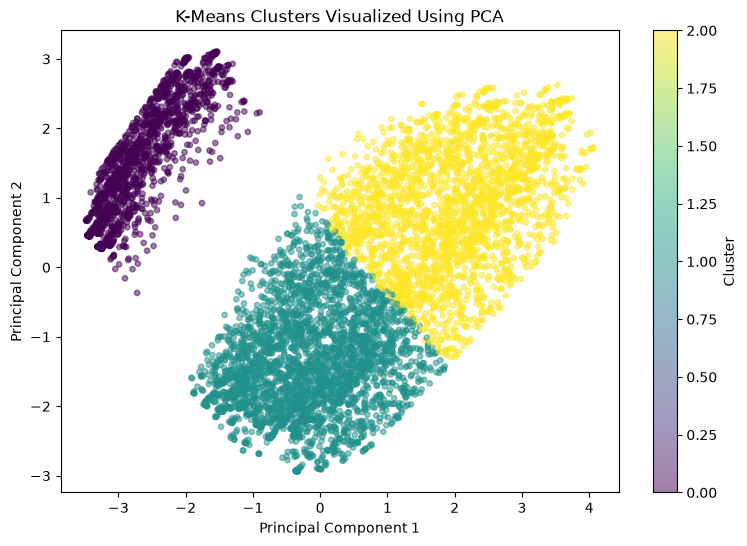

In [28]:
plt.figure(figsize=(9, 6))

scatter = plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=final_labels,
    cmap="viridis",
    alpha=0.5,
    s=15
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("K-Means Clusters Visualized Using PCA")
plt.colorbar(scatter, label="Cluster")
plt.show()

In [29]:
feature_names = preprocessor.get_feature_names_out()

loadings = pd.DataFrame(
    pca.components_.T,
    index=feature_names,
    columns=["PC1", "PC2"]
)

for pc in ["PC1", "PC2"]:
    print(f"\nTop features contributing to {pc}:")
    print(
        loadings[pc]
        .abs()
        .sort_values(ascending=False)
        .head(10)
    )



Top features contributing to PC1:
num__MonthlyCharges                          0.493369
num__TotalCharges                            0.461362
num__tenure                                  0.303002
cat__StreamingTV_No internet service         0.168444
cat__InternetService_No                      0.168444
cat__StreamingMovies_No internet service     0.168444
cat__OnlineSecurity_No internet service      0.168444
cat__OnlineBackup_No internet service        0.168444
cat__TechSupport_No internet service         0.168444
cat__DeviceProtection_No internet service    0.168444
Name: PC1, dtype: float64

Top features contributing to PC2:
num__tenure                     0.490514
num__TotalCharges               0.306561
cat__Contract_Month-to-month    0.248349
cat__TechSupport_No             0.213777
cat__OnlineSecurity_No          0.207985
cat__DeviceProtection_No        0.203219
cat__OnlineBackup_No            0.193792
cat__Contract_Two year          0.183242
num__SeniorCitizen              0.17

PCA reduced the dataset from 45 features to 2 principal components. PC1 explains 27.22% of the variance, and PC2 explains 18.10%, giving a total of 45.32%. PC1 is mainly influenced by MonthlyCharges, TotalCharges, and tenure, while PC2 is influenced by tenure, TotalCharges, contract type, and additional services. Therefore, the two components mainly represent customer spending, tenure, and service behavior. However, 54.68% of the variance is not represented in this 2D visualization.

In [30]:
kmeans_pca = KMeans(
    n_clusters=3,
    init="k-means++",
    n_init=10,
    random_state=42
)

labels_pca = kmeans_pca.fit_predict(X_pca)

print("Original K-Means inertia:", final_kmeans.inertia_)
print("PCA K-Means inertia:", kmeans_pca.inertia_)

print("\nOriginal K-Means silhouette:",
      silhouette_score(X_processed, final_labels, sample_size=2000, random_state=42))

print("PCA K-Means silhouette:",
      silhouette_score(X_pca, labels_pca, sample_size=2000, random_state=42))

Original K-Means inertia: 55586.85345796538
PCA K-Means inertia: 8579.171730793336

Original K-Means silhouette: 0.23833276180591534
PCA K-Means silhouette: 0.5614676227859227


Applying K-Means after PCA increased the silhouette score from 0.2383 to 0.5615. This suggests that the clusters are more separated in the two-dimensional PCA space. PCA may have removed some less useful variation and made clustering easier. However, the two components preserve only 45.32% of the original variance, so some important information may have been lost. Therefore, the higher silhouette score does not necessarily mean the PCA clusters are more meaningful.

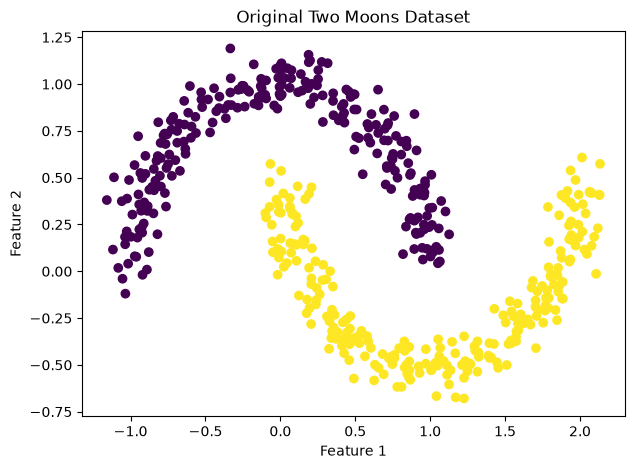

In [36]:
from sklearn.datasets import make_moons

X_moons, y_moons = make_moons(
    n_samples=500,
    noise=0.08,
    random_state=42
)

plt.figure(figsize=(7, 5))
plt.scatter(
    X_moons[:, 0],
    X_moons[:, 1],
    c=y_moons,
    cmap="viridis"
)
plt.title("Original Two Moons Dataset")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()

In [33]:
kmeans_moons = KMeans(
    n_clusters=2,
    init="k-means++",
    n_init=10,
    random_state=42
)

moon_labels = kmeans_moons.fit_predict(X_moons)

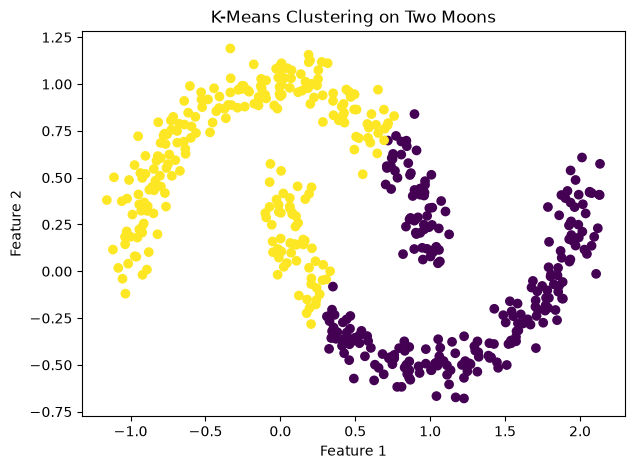

In [34]:
plt.figure(figsize=(7, 5))

plt.scatter(
    X_moons[:, 0],
    X_moons[:, 1],
    c=moon_labels,
    cmap="viridis"
)

plt.title("K-Means Clustering on Two Moons")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()

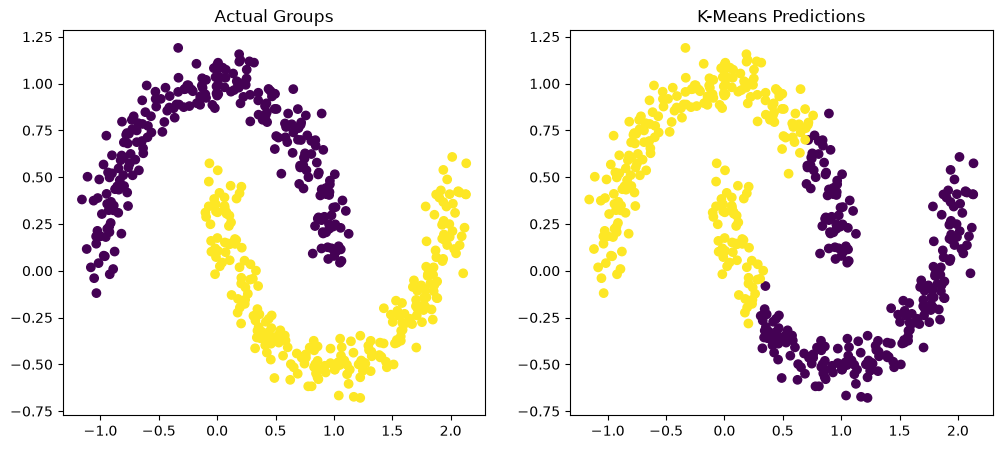

In [35]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].scatter(
    X_moons[:, 0],
    X_moons[:, 1],
    c=y_moons,
    cmap="viridis"
)
axes[0].set_title("Actual Groups")

axes[1].scatter(
    X_moons[:, 0],
    X_moons[:, 1],
    c=moon_labels,
    cmap="viridis"
)
axes[1].set_title("K-Means Predictions")

plt.show()

In [38]:
moon_score = silhouette_score(X_moons, moon_labels)

print("K-Means Silhouette Score:", moon_score)

K-Means Silhouette Score: 0.48575889299924385


K-Means limitation on non-globular clusters

K-Means struggles with the two-moons dataset because the clusters have curved shapes. It uses distances from cluster centroids and tends to create roughly spherical clusters. Therefore, it cannot properly identify complex shapes such as curved or irregular clusters. This demonstrates that K-Means is not suitable for every dataset.

Two-Moons Experiment Results

K-Means achieved a silhouette score of 0.4858 on the two-moons dataset. However, the score does not guarantee that the algorithm correctly identified the actual moon-shaped groups. K-Means relies on distances to centroids and tends to form spherical clusters, making it unsuitable for complex, curved cluster shapes. This experiment demonstrates an important limitation of K-Means.